the first thing to do is explore the data

In [102]:
import numpy as np 
import pandas as pd 

In [103]:
applications = pd.read_csv('dataset/application_record.csv')
records= pd.read_csv('dataset/credit_record.csv')
applications.shape, records.shape

((438557, 18), (1048575, 3))

In [104]:
applications.head()

,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
1,5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
2,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0
3,5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
4,5008809,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0


In [105]:
records.head()

,ID,MONTHS_BALANCE,STATUS
0,5001711,0,X
1,5001711,-1,0
2,5001711,-2,0
3,5001711,-3,0
4,5001712,0,C


In [106]:
len(records.ID.unique())

45985

In [107]:
records[records.ID.duplicated()]

,ID,MONTHS_BALANCE,STATUS
1,5001711,-1,0
2,5001711,-2,0
3,5001711,-3,0
5,5001712,-1,C
6,5001712,-2,C
...,...,...,...
1048570,5150487,-25,C
1048571,5150487,-26,C
1048572,5150487,-27,C
1048573,5150487,-28,C


In [108]:
records[records.ID == 5001711]

,ID,MONTHS_BALANCE,STATUS
0,5001711,0,X
1,5001711,-1,0
2,5001711,-2,0
3,5001711,-3,0


the way that the data is formatted is by giving the months balance for a certain month along with that month's status. 
to determine the creditworthiness of the customer, I will sum over the customer's past history to capture past missed payments. 

In [109]:
# check for null s
records.isnull().sum()

ID                0
MONTHS_BALANCE    0
STATUS            0
dtype: int64

In [110]:
# map the status to the right level 
# using ordinal encoding 
'''
the description for the feature is: 
0: 1-29 days past due 
1: 30-59 days past due 
2: 60-89 days overdue 
3: 90-119 days overdue 
4: 120-149 days overdue 
5: Overdue or bad debts, write-offs for more than 150 days 
C: paid off that month 
X: No loan for the month
'''

# convert this feature into: 
'''
the description for the feature is: 
0: No loan for the month
1: paid off that month 
2: 1-29 days past due 
3: 30-59 days past due 
4: 60-89 days overdue 
5: 90-119 days overdue 
6: 120-149 days overdue 
7: Overdue or bad debts, write-offs for more than 150 days 
'''

# higher values indicate lower creditworthiness 

from sklearn.preprocessing import OrdinalEncoder

In [111]:
categories= ['X' , 'C' ] +  [str(i) for i in range(0, 6 )]
print(categories)

encoder= OrdinalEncoder(categories= [categories])
records['status_encoded'] = encoder.fit_transform(records[['STATUS']])

records.head()

['X', 'C', '0', '1', '2', '3', '4', '5']


,ID,MONTHS_BALANCE,STATUS,status_encoded
0,5001711,0,X,0.0
1,5001711,-1,0,2.0
2,5001711,-2,0,2.0
3,5001711,-3,0,2.0
4,5001712,0,C,1.0


In [112]:
# begin summing over all the balance 
# higher score for status summed indicates lower creditworthiness 

records_grouped= records.groupby(by= 'ID' , axis = 0)
for i in records_grouped: 
    print(i) 
    break 

/var/folders/j3/tjmkthlx1bn1l50f7k39nd480000gn/T/ipykernel_7795/1736641320.py:4: FutureWarning: The 'axis' keyword in DataFrame.groupby is deprecated and will be removed in a future version.
  records_grouped= records.groupby(by= 'ID' , axis = 0)


(5001711,         ID  MONTHS_BALANCE STATUS  status_encoded
0  5001711               0      X             0.0
1  5001711              -1      0             2.0
2  5001711              -2      0             2.0
3  5001711              -3      0             2.0)


In [113]:
# to sum, use agg() --> for each group in groupby
# transform() --> for each instance in record 

records_grouped.status_encoded.agg(summed= 'sum')

,summed
ID,
5001711,6.0
5001712,29.0
5001713,0.0
5001714,0.0
5001715,0.0
...,...
5150482,30.0
5150483,0.0
5150484,25.0


In [114]:
# transform will be easier 
records['summed'] = records_grouped.status_encoded.transform('sum')
records.head()

,ID,MONTHS_BALANCE,STATUS,status_encoded,summed
0,5001711,0,X,0.0,6.0
1,5001711,-1,0,2.0,6.0
2,5001711,-2,0,2.0,6.0
3,5001711,-3,0,2.0,6.0
4,5001712,0,C,1.0,29.0


In [115]:
# now just get the unique ids 
creditworthiness= records.copy(deep = True)
# creditworthiness= creditworthiness[creditworthiness.ID.duplicated() == False ]
creditworthiness.drop_duplicates(subset='ID', inplace= True)
creditworthiness.drop(labels= ['MONTHS_BALANCE', 'STATUS', 'status_encoded'], axis= 1 , inplace= True) 
creditworthiness     


,ID,summed
0,5001711,6.0
4,5001712,29.0
23,5001713,0.0
45,5001714,0.0
60,5001715,0.0
...,...,...
1048494,5150482,30.0
1048512,5150483,0.0
1048530,5150484,25.0
1048543,5150485,4.0


to turn this into a classification problem, I want to view and understand the risk/creditworthiness of each customer
note that lower scores for summed indicate higher levels of creditworthiness 

In [116]:
import seaborn as sns 
import matplotlib.pyplot as plt

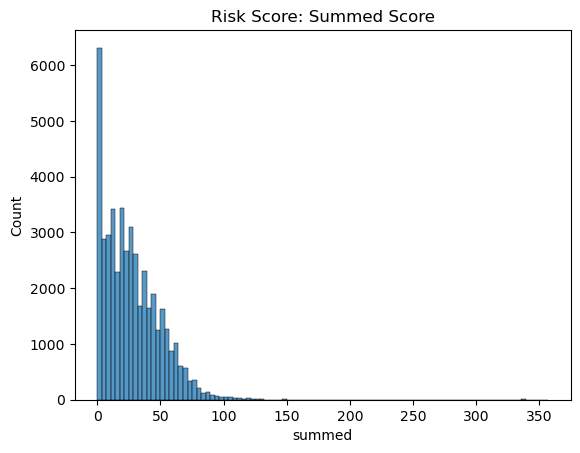

In [117]:
sns.histplot(creditworthiness.summed, bins= 100 )
plt.title('Risk Score: Summed Score')
plt.savefig('images/summed_score.png')
plt.show()

in order to split up the categorization of customers, the following will be the criteria: 
- 0 is very creditworthy -- automatic approval 
- the rest will be scored by placing into bins of standard deviations (excluding 0 risk scores)
    - describe is splittng into quartiles from median, instead use the mean and standard deviations to get the right bin boundaries 

In [118]:
score_mean= creditworthiness.summed.where(creditworthiness.summed > 0 ).mean()
score_std= creditworthiness.summed.where(creditworthiness.summed > 0 ).std()
score_mean, score_std

(np.float64(30.39402639388164), 21.51604929727674)

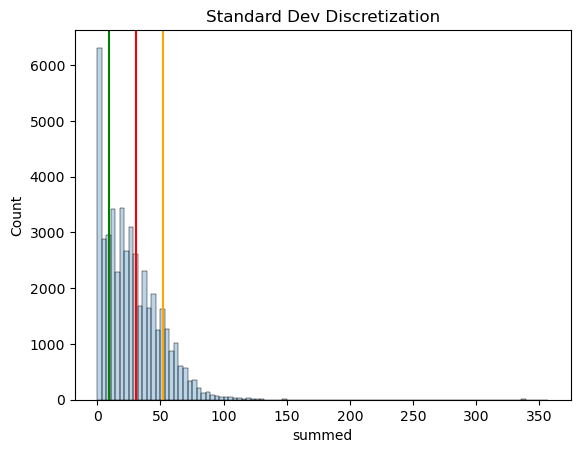

In [119]:
sns.histplot(creditworthiness.summed, bins  = 100 , alpha= .3,  label= '- summed score' )
plt.axvline(x= score_mean, label= 'medium', color= 'red')
plt.axvline(x= ( score_mean- score_std), label= 'low', color= 'green')
plt.axvline(x=  (score_mean+ score_std), label= 'high', color= 'orange')
# plt.legend()
plt.title('Standard Dev Discretization')
plt.savefig('images/standard_def_discretization.png')
plt.show()

the mapping will be as follows (feature summed), higher summed scores = more defaults on loans = higher risk : 
- 0 = no risk 
-  (0, score_mean- score_std] = low risk 
- (score_mean-score_std, score_mean] = medium low risk 
- (score_mean, score_mean-score_std] = medium high risk 
- (score_mean-score_std, inf) = high risk 

as a result, the classification will be over 5 labels 


In [120]:
# pd.cut is right selctive ( , ] ranges with right= True setting 
ranges= (-float('inf'),0, score_mean- score_std, score_mean, score_mean + score_std, float('inf'))
range_titles= ('none', 'low', 'medium_low', 'medium_high', 'high')

print(ranges)

creditworthiness['risk_level']= pd.cut(creditworthiness['summed'], bins=ranges, labels=range_titles, right= True)
creditworthiness


(-inf, 0, np.float64(8.877977096604898), np.float64(30.39402639388164), np.float64(51.91007569115838), inf)


,ID,summed,risk_level
0,5001711,6.0,low
4,5001712,29.0,medium_low
23,5001713,0.0,none
45,5001714,0.0,none
60,5001715,0.0,none
...,...,...,...
1048494,5150482,30.0,medium_low
1048512,5150483,0.0,none
1048530,5150484,25.0,medium_low
1048543,5150485,4.0,low


In [121]:
from sklearn.preprocessing import OrdinalEncoder
encoder= OrdinalEncoder(categories= [range_titles])
creditworthiness['risk'] = encoder.fit_transform(creditworthiness[['risk_level']])
creditworthiness.head()

,ID,summed,risk_level,risk
0,5001711,6.0,low,1.0
4,5001712,29.0,medium_low,2.0
23,5001713,0.0,none,0.0
45,5001714,0.0,none,0.0
60,5001715,0.0,none,0.0


In [122]:
creditworthiness.drop(labels= [ 'summed', 'risk_level'], axis= 1, inplace= True)
creditworthiness.head()

,ID,risk
0,5001711,1.0
4,5001712,2.0
23,5001713,0.0
45,5001714,0.0
60,5001715,0.0


creditworthiness is determined for the customers who already have a record of credit history
the next thing to do is look at application record, process it, and join with the ID if needed 

In [124]:
applications

,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
1,5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
2,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0
3,5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
4,5008809,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
438552,6840104,M,N,Y,0,135000.0,Pensioner,Secondary / secondary special,Separated,House / apartment,-22717,365243,1,0,0,0,NaN,1.0
438553,6840222,F,N,N,0,103500.0,Working,Secondary / secondary special,Single / not married,House / apartment,-15939,-3007,1,0,0,0,Laborers,1.0
438554,6841878,F,N,N,0,54000.0,Commercial associate,Higher education,Single / not married,With parents,-8169,-372,1,1,0,0,Sales staff,1.0
438555,6842765,F,N,Y,0,72000.0,Pensioner,Secondary / secondary special,Married,House / apartment,-21673,365243,1,0,0,0,NaN,2.0


### application record processing
convert the categorical features into proper encoding (label encoding, ordinal encoding, one hot encoding, ect...), then remove redundant features 

- this will eventually be done with sklearn Pipeline to simplify model deployment 
- first ensure that the way that each feature should be processed, data exploration 

In [127]:
applications.describe()

,ID,CNT_CHILDREN,AMT_INCOME_TOTAL,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS
count,4.385570e+05,438557.000000,4.385570e+05,438557.000000,438557.000000,438557.0,438557.000000,438557.000000,438557.000000,438557.000000
mean,6.022176e+06,0.427390,1.875243e+05,-15997.904649,60563.675328,1.0,0.206133,0.287771,0.108207,2.194465
std,5.716370e+05,0.724882,1.100869e+05,4185.030007,138767.799647,0.0,0.404527,0.452724,0.310642,0.897207
min,5.008804e+06,0.000000,2.610000e+04,-25201.000000,-17531.000000,1.0,0.000000,0.000000,0.000000,1.000000
25%,5.609375e+06,0.000000,1.215000e+05,-19483.000000,-3103.000000,1.0,0.000000,0.000000,0.000000,2.000000
50%,6.047745e+06,0.000000,1.607805e+05,-15630.000000,-1467.000000,1.0,0.000000,0.000000,0.000000,2.000000
75%,6.456971e+06,1.000000,2.250000e+05,-12514.000000,-371.000000,1.0,0.000000,1.000000,0.000000,3.000000
max,7.999952e+06,19.000000,6.750000e+06,-7489.000000,365243.000000,1.0,1.000000,1.000000,1.000000,20.000000


In [129]:
applications.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 438557 entries, 0 to 438556
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ID                   438557 non-null  int64  
 1   CODE_GENDER          438557 non-null  object 
 2   FLAG_OWN_CAR         438557 non-null  object 
 3   FLAG_OWN_REALTY      438557 non-null  object 
 4   CNT_CHILDREN         438557 non-null  int64  
 5   AMT_INCOME_TOTAL     438557 non-null  float64
 6   NAME_INCOME_TYPE     438557 non-null  object 
 7   NAME_EDUCATION_TYPE  438557 non-null  object 
 8   NAME_FAMILY_STATUS   438557 non-null  object 
 9   NAME_HOUSING_TYPE    438557 non-null  object 
 10  DAYS_BIRTH           438557 non-null  int64  
 11  DAYS_EMPLOYED        438557 non-null  int64  
 12  FLAG_MOBIL           438557 non-null  int64  
 13  FLAG_WORK_PHONE      438557 non-null  int64  
 14  FLAG_PHONE           438557 non-null  int64  
 15  FLAG_EMAIL       

In [134]:
categorical_features= []
for c in applications.columns: 
    if applications[c].dtype == 'object': 
        categorical_features.append(c)

categorical_features

['CODE_GENDER',
 'FLAG_OWN_CAR',
 'FLAG_OWN_REALTY',
 'NAME_INCOME_TYPE',
 'NAME_EDUCATION_TYPE',
 'NAME_FAMILY_STATUS',
 'NAME_HOUSING_TYPE',
 'OCCUPATION_TYPE']

these categorical features should be encoded in various ways which best fit the feature 
- code gender = nominal 
- flag own car = ordinal (0 no, 1 yes)
- flag own realty = ordinal (0 no, 1 yes)
- name income type = nominal 
- name education type = ordinal (0 for lowest)
- name family status = nominal 
- name housing status= nominal 
- occupation type = nominal (note there are nulls)

In [193]:
applications.NAME_EDUCATION_TYPE.unique()

array(['Higher education', 'Secondary / secondary special',
       'Incomplete higher', 'Lower secondary', 'Academic degree'],
      dtype=object)

In [ ]:
# see how pipeline works 
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

ordinal_features= ['FLAG_OWN_CAR','FLAG_OWN_REALTY' ]


ordinal_preprocessor= OrdinalEncoder(categories=[['N', 'Y'], ['N', 'Y']]) # encoder for 2 features 

column_transformer = ColumnTransformer(
    transformers=[
    ('ordinal_cols', ordinal_preprocessor, ordinal_features ) # pass through multiple cols into encoder 
    # requires multiple features in categrories 
], 
remainder= 'passthrough', verbose_feature_names_out= False )

# make pipeline 
pipe= Pipeline(steps = [
    ('data_transform', column_transformer)
])

pipe.fit(applications)

,steps,"[('data_transform', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('ordinal_cols', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


In [191]:
column_transformer.get_feature_names_out()

array(['FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'ID', 'CODE_GENDER',
       'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'NAME_INCOME_TYPE',
       'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE',
       'DAYS_BIRTH', 'DAYS_EMPLOYED', 'FLAG_MOBIL', 'FLAG_WORK_PHONE',
       'FLAG_PHONE', 'FLAG_EMAIL', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS'],
      dtype=object)

In [185]:
pd.DataFrame(pipe.transform(applications), columns=applications.columns)

,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,1.0,1.0,5008804,M,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
1,1.0,1.0,5008805,M,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
2,1.0,1.0,5008806,M,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0
3,0.0,1.0,5008808,F,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
4,0.0,1.0,5008809,F,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
438552,0.0,1.0,6840104,M,0,135000.0,Pensioner,Secondary / secondary special,Separated,House / apartment,-22717,365243,1,0,0,0,NaN,1.0
438553,0.0,0.0,6840222,F,0,103500.0,Working,Secondary / secondary special,Single / not married,House / apartment,-15939,-3007,1,0,0,0,Laborers,1.0
438554,0.0,0.0,6841878,F,0,54000.0,Commercial associate,Higher education,Single / not married,With parents,-8169,-372,1,1,0,0,Sales staff,1.0
438555,0.0,1.0,6842765,F,0,72000.0,Pensioner,Secondary / secondary special,Married,House / apartment,-21673,365243,1,0,0,0,NaN,2.0


then, scale as needed 
do pca to drop uneeded cols (if one hot encoding, use ordinal/nominal encoding to remove features first)